# 2. Training and evaluation

Two 3D U-Nets are trained on the same subjects: one for all 45 classes and one for the 28-class reduced set.
Both are then tested at the original 1 mm resolution on subjects they never saw.

The question is whether asking the network for the 17 extra structures costs accuracy on the
27 structures both models share.

Needs a GPU: Runtime > Change runtime type > T4 GPU. Training saves a checkpoint to Drive after every epoch,
so if Colab disconnects, run all cells again and it continues where it stopped.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q monai nibabel

import os, sys, zipfile
DRIVE = '/content/drive/MyDrive'

# the wbseg code: use the folder in My Drive, or unpack wbseg.zip there the first time
if not os.path.exists(f'{DRIVE}/wbseg/__init__.py'):
    if os.path.exists(f'{DRIVE}/wbseg.zip'):
        zipfile.ZipFile(f'{DRIVE}/wbseg.zip').extractall(DRIVE)
        print('unpacked wbseg.zip into My Drive')
    else:
        raise SystemExit('wbseg not found. Upload wbseg.zip to My Drive (not inside any folder) and run this cell again.')
sys.path.insert(0, DRIVE)
import wbseg
print('using wbseg from', os.path.dirname(wbseg.__file__))

OUT_DIR = f'{DRIVE}/wbseg_outputs'   # results and figures are saved here
os.makedirs(OUT_DIR, exist_ok=True)
os.chdir(OUT_DIR)

Mounted at /content/drive
unpacked wbseg.zip into My Drive
using wbseg from /content/drive/MyDrive/wbseg


In [ ]:
IMAGE_DIR = "/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Image_Folder"
LABEL_DIR = "/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Label_Folder"
LUT_PATH = "/content/drive/MyDrive/FreeSurferColorLUT.txt"   # optional, only for FreeSurfer colours
RUN_DIR = "/content/drive/MyDrive/wbseg_outputs/runs"         # checkpoints, best models and test predictions

if not os.path.exists(LUT_PATH):
    LUT_PATH = None
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [ ]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from monai.data import CacheDataset, DataLoader
from monai.utils import set_determinism

from wbseg.data import find_pairs, split_subjects, save_split, get_transforms
from wbseg.labels import LABEL_SETS, REDUCED_LABELS, colour_table
from wbseg.train import build_model, train
from wbseg.evaluate import evaluate, summarise, predict
from wbseg import plots

SEED = 0
SIZE = 128          # the whole head is resized to SIZE^3 for the network
N_VAL, N_TEST = 18, 30
MAX_EPOCHS = 150
set_determinism(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU, otherwise training will take days.")

device: cuda


## Split

Subjects are split once at random, and the same split is used for both models.

In [ ]:
pairs = find_pairs(IMAGE_DIR, LABEL_DIR)
if len(pairs) < N_VAL + N_TEST + 2:
    raise SystemExit(f"Only {len(pairs)} scans found. Check IMAGE_DIR and LABEL_DIR in the second code cell.")

split = split_subjects(pairs, n_val=N_VAL, n_test=N_TEST, seed=SEED)
save_split(split, "results/data_split.json")
print({k: len(v) for k, v in split.items()})

found 148 images in /content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Image_Folder
found 148 label maps in /content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Label_Folder
{'train': 100, 'val': 18, 'test': 30}


## Training

In [5]:
histories = {}
for name, labels in LABEL_SETS.items():
    print(f"\n=== {name} label set: {len(labels)} classes ===")
    train_ds = CacheDataset(split["train"], get_transforms(labels, SIZE, train=True), num_workers=2)
    val_ds = CacheDataset(split["val"], get_transforms(labels, SIZE), num_workers=2)
    train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=1, num_workers=1)
    model = build_model(len(labels))
    histories[name] = train(model, train_loader, val_loader, len(labels),
                            out_dir=f"{RUN_DIR}/{name}", max_epochs=MAX_EPOCHS,
                            val_every=2, patience=15, device=device)
    del train_ds, val_ds


=== full label set: 45 classes ===


Loading dataset: 100%|██████████| 18/18 [00:39<00:00,  2.20s/it]


epoch 1/150  loss 1.6269  [29s]
epoch 2/150  loss 1.1168  val Dice 0.0349  (best)  [28s]
epoch 3/150  loss 1.0139  [28s]
epoch 4/150  loss 0.8727  val Dice 0.3041  (best)  [30s]
epoch 5/150  loss 0.7590  [29s]
epoch 6/150  loss 0.6745  val Dice 0.4402  (best)  [32s]
epoch 7/150  loss 0.5907  [30s]
epoch 8/150  loss 0.5261  val Dice 0.4810  (best)  [31s]
epoch 9/150  loss 0.4865  [30s]
epoch 10/150  loss 0.4504  val Dice 0.6263  (best)  [31s]
epoch 11/150  loss 0.4367  [30s]
epoch 12/150  loss 0.4098  val Dice 0.6348  (best)  [32s]
epoch 13/150  loss 0.3925  [30s]
epoch 14/150  loss 0.3915  val Dice 0.6708  (best)  [32s]
epoch 15/150  loss 0.3817  [30s]
epoch 16/150  loss 0.3583  val Dice 0.7025  (best)  [32s]
epoch 17/150  loss 0.3552  [30s]
epoch 18/150  loss 0.3572  val Dice 0.7069  (best)  [32s]
epoch 19/150  loss 0.3476  [30s]
epoch 20/150  loss 0.3394  val Dice 0.7079  (best)  [31s]
epoch 21/150  loss 0.3435  [31s]
epoch 22/150  loss 0.3347  val Dice 0.7178  (best)  [32s]
epoch 23

Loading dataset: 100%|██████████| 18/18 [00:25<00:00,  1.43s/it]


epoch 1/150  loss 1.6098  [22s]
epoch 2/150  loss 1.0860  val Dice 0.0274  (best)  [23s]
epoch 3/150  loss 0.9539  [23s]
epoch 4/150  loss 0.7797  val Dice 0.2906  (best)  [23s]
epoch 5/150  loss 0.6209  [25s]
epoch 6/150  loss 0.4794  val Dice 0.6599  (best)  [24s]
epoch 7/150  loss 0.3969  [23s]
epoch 8/150  loss 0.3767  val Dice 0.7225  (best)  [29s]
epoch 9/150  loss 0.3474  [25s]
epoch 10/150  loss 0.3201  val Dice 0.7553  (best)  [24s]
epoch 11/150  loss 0.3118  [22s]
epoch 12/150  loss 0.3040  val Dice 0.7642  (best)  [24s]
epoch 13/150  loss 0.3006  [23s]
epoch 14/150  loss 0.2938  val Dice 0.7473  [24s]
epoch 15/150  loss 0.2907  [26s]
epoch 16/150  loss 0.2746  val Dice 0.7697  (best)  [24s]
epoch 17/150  loss 0.2805  [24s]
epoch 18/150  loss 0.2643  val Dice 0.7869  (best)  [23s]
epoch 19/150  loss 0.2652  [25s]
epoch 20/150  loss 0.2623  val Dice 0.7919  (best)  [25s]
epoch 21/150  loss 0.2618  [22s]
epoch 22/150  loss 0.2529  val Dice 0.7890  [23s]
epoch 23/150  loss 0.255

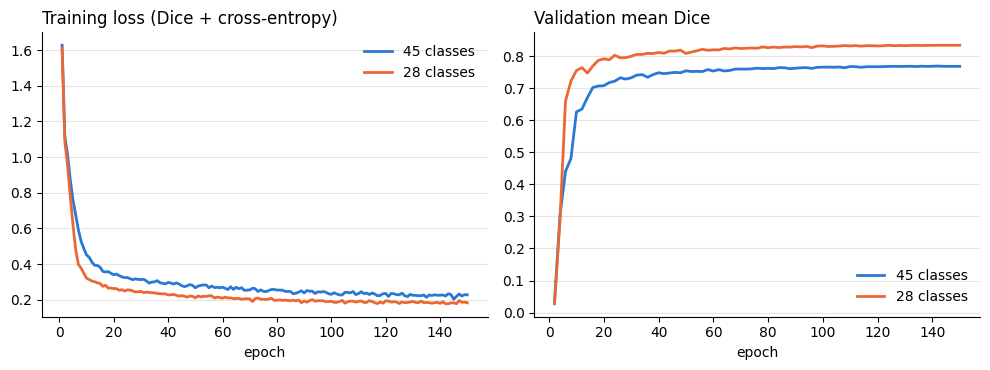

In [6]:
fig = plots.training_curves({"45 classes": histories["full"], "28 classes": histories["reduced"]})
fig.savefig("figures/training_curves.png", dpi=150)
plt.show()

## Test set

Each test scan is segmented, the class scores are resized back to 256^3 and Dice is computed against the
original FreeSurfer label map. Predictions are saved to Drive with FreeSurfer label values, so they open in
any viewer (FreeView, ITK-SNAP) on top of the T1.

In [7]:
results = {}
for name, labels in LABEL_SETS.items():
    model = build_model(len(labels)).to(device)
    model.load_state_dict(torch.load(f"{RUN_DIR}/{name}/best_model.pt", map_location=device))
    results[name] = evaluate(model, split["test"], labels, SIZE,
                             save_dir=f"{RUN_DIR}/{name}/test_predictions", device=device)
    results[name].to_csv(f"results/test_dice_{name}.csv", index=False)

[1/30] OAS30028_MR_d0043  mean Dice 0.7752
[2/30] OAS30036_MR_d0059  mean Dice 0.7505
[3/30] OAS30039_MR_d1203  mean Dice 0.7231
[4/30] OAS30071_MR_d1627  mean Dice 0.7347
[5/30] OAS30074_MR_d2812  mean Dice 0.7481
[6/30] OAS30080_MR_d1318  mean Dice 0.7368
[7/30] OAS30085_MR_d1566  mean Dice 0.7352
[8/30] OAS30087_MR_d0260  mean Dice 0.7709
[9/30] OAS30088_MR_d0093  mean Dice 0.7420
[10/30] OAS30105_MR_d0056  mean Dice 0.7482
[11/30] OAS30108_MR_d0168  mean Dice 0.5262
[12/30] OAS30117_MR_d4155  mean Dice 0.7198
[13/30] OAS30131_MR_d1901  mean Dice 0.7601
[14/30] OAS30134_MR_d1642  mean Dice 0.7480
[15/30] OAS30137_MR_d4525  mean Dice 0.7406
[16/30] OAS30143_MR_d3509  mean Dice 0.7665
[17/30] OAS30146_MR_d1042  mean Dice 0.7594
[18/30] OAS30147_MR_d0048  mean Dice 0.7434
[19/30] OAS30149_MR_d0051  mean Dice 0.7504
[20/30] OAS30151_MR_d0064  mean Dice 0.7454
[21/30] OAS30152_MR_d0111  mean Dice 0.7419
[22/30] OAS30155_MR_d1934  mean Dice 0.7632
[23/30] OAS30158_MR_d2467  mean Dice 0.52

In [ ]:
full_table = summarise(results["full"])
red_table = summarise(results["reduced"])
full_table.to_csv("results/dice_per_structure_full.csv", index=False)
red_table.to_csv("results/dice_per_structure_reduced.csv", index=False)
full_table

## Full vs reduced on the 27 shared structures

In [ ]:
shared = REDUCED_LABELS[1:]

def subject_means(res):
    r = res[res["label"].isin(shared)]
    return r.groupby("id")["dice"].mean()

a, b = subject_means(results["full"]), subject_means(results["reduced"])
a, b = a.loc[b.index], b
stat, p = wilcoxon(a, b)
comparison = pd.DataFrame({"45 classes": a, "28 classes": b})
print(comparison.describe().loc[["mean", "std", "min", "max"]].round(4))
print(f"\npaired difference (45 - 28): {(a - b).mean():+.4f}")
print(f"Wilcoxon signed-rank test over {len(a)} test subjects: p = {p:.3g}")

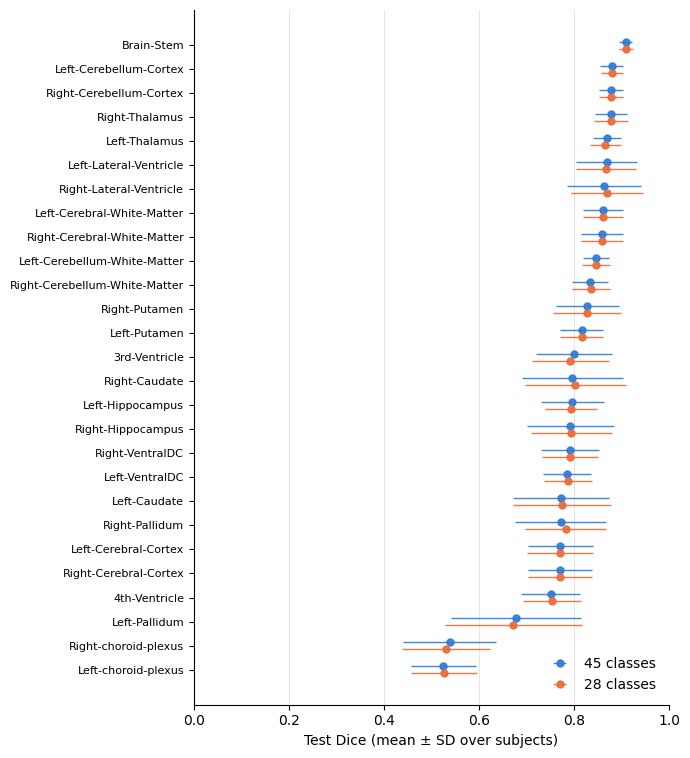

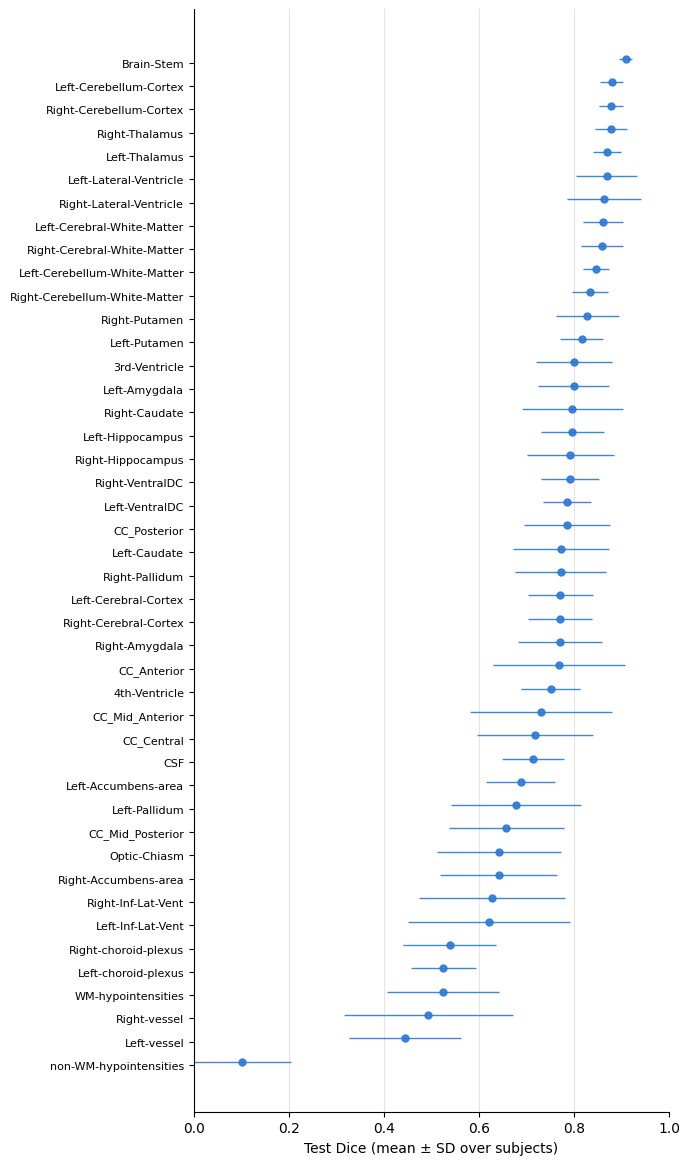

In [10]:
fig = plots.dice_by_structure([full_table[full_table["label"].isin(shared)], red_table])
fig.savefig("figures/dice_shared_structures.png", dpi=150)
plt.show()

fig = plots.dice_by_structure([full_table], names=("45 classes",))
fig.savefig("figures/dice_all_structures.png", dpi=150)
plt.show()

## Example test subject

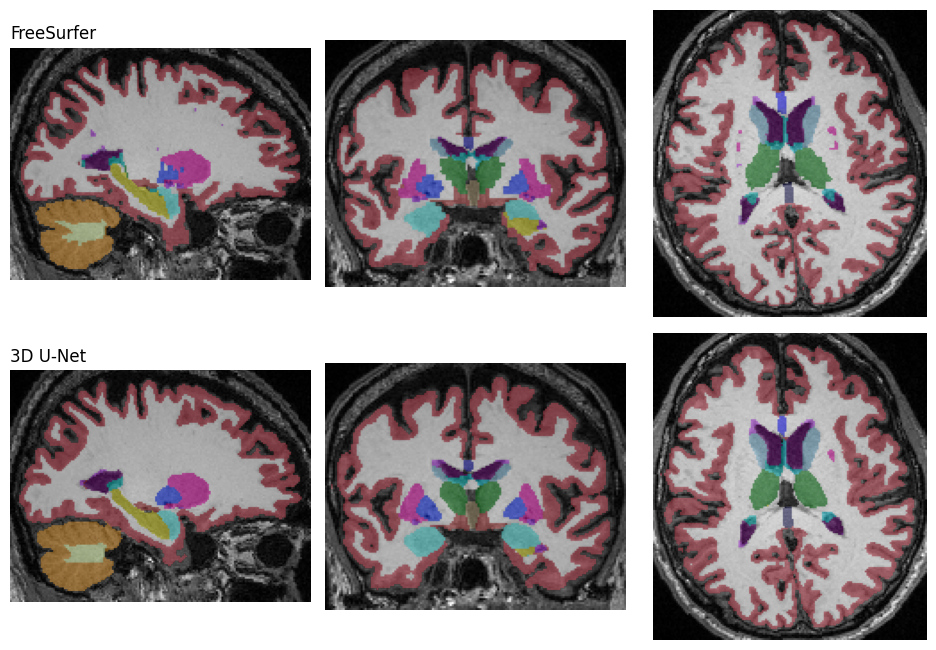

In [11]:
import nibabel as nib
labels = LABEL_SETS["full"]
case = split["test"][0]
img = nib.as_closest_canonical(nib.load(case["image"]))
truth = nib.as_closest_canonical(nib.load(case["label"]))
pred = nib.as_closest_canonical(nib.load(f"{RUN_DIR}/full/test_predictions/{case['id']}_pred.nii.gz"))
fig = plots.comparison_figure(img.get_fdata(), np.asarray(truth.dataobj).astype(int),
                              np.asarray(pred.dataobj).astype(int), labels, colour_table(labels, LUT_PATH),
                              index=(100, 128, 140))
fig.savefig("figures/example_segmentation.png", dpi=150)
plt.show()

## Summary

Writes the main numbers to `results/summary.md`.

In [12]:
def mean_sd(res, labs=None):
    r = res if labs is None else res[res["label"].isin(labs)]
    m = r.groupby("id")["dice"].mean()
    return f"{m.mean():.3f} ± {m.std():.3f}"

lines = [
    "# Test results", "",
    f"Split: {len(split['train'])} train, {len(split['val'])} validation, {len(split['test'])} test scans (seed {SEED}).", "",
    "Mean Dice per subject, averaged over structures, then mean ± SD over test subjects.", "",
    "| Model | All its structures | 27 shared structures |",
    "|---|---|---|",
    f"| 45 classes | {mean_sd(results['full'])} | {mean_sd(results['full'], shared)} |",
    f"| 28 classes | {mean_sd(results['reduced'])} | {mean_sd(results['reduced'], shared)} |", "",
    f"Paired difference on the shared structures: {(a - b).mean():+.4f} (Wilcoxon signed-rank p = {p:.3g}).", "",
    "Best five structures (45 classes): " + ", ".join(f"{s} {m:.3f}" for s, m in full_table[["structure", "mean"]].head(5).values),
    "", "Worst five structures (45 classes): " + ", ".join(f"{s} {m:.3f}" for s, m in full_table[["structure", "mean"]].tail(5).values),
]
open("results/summary.md", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))

# Test results

Split: 100 train, 18 validation, 30 test scans (seed 0).

Mean Dice per subject, averaged over structures, then mean ± SD over test subjects.

| Model | All its structures | 27 shared structures |
|---|---|---|
| 45 classes | 0.733 ± 0.057 | 0.797 ± 0.047 |
| 28 classes | 0.798 ± 0.047 | 0.798 ± 0.047 |

Paired difference on the shared structures: -0.0003 (Wilcoxon signed-rank p = 0.328).

Best five structures (45 classes): Brain-Stem 0.909, Left-Cerebellum-Cortex 0.880, Right-Cerebellum-Cortex 0.878, Right-Thalamus 0.877, Left-Thalamus 0.870

Worst five structures (45 classes): Left-choroid-plexus 0.525, WM-hypointensities 0.524, Right-vessel 0.493, Left-vessel 0.444, non-WM-hypointensities 0.101
